In [2]:
!pip install git+https://github.com/openai/CLIP.git

  Cloning https://github.com/openai/CLIP.git to /tmp/pip-req-build-lk0gz0cf
  Running command git clone --filter=blob:none --quiet https://github.com/openai/CLIP.git /tmp/pip-req-build-lk0gz0cf
  Resolved https://github.com/openai/CLIP.git to commit dcba3cb2e2827b402d2701e7e1c7d9fed8a20ef1
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 1.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.7 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 78.9 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 67.6 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 45.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.6 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 6.2 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB

In [12]:
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import pandas as pd
import numpy as np
from PIL import Image
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.preprocessing import label_binarize
from tqdm import tqdm
import clip
from clip.simple_tokenizer import SimpleTokenizer as _Tokenizer
from collections import OrderedDict
import copy
import matplotlib.pyplot as plt

_tokenizer = _Tokenizer()

# ============================================================================
# Dataset and Data Loading
# ============================================================================

class OrthonetDataset(Dataset):
    """Orthonet dataset for CLIP-based models"""
    
    def __init__(self, df, images_root, preprocess=None, label_encoder=None):
        self.df = df.reset_index(drop=True)
        self.images_root = images_root
        self.preprocess = preprocess
        self.label_encoder = label_encoder
        
        # Encode labels
        if self.label_encoder is None:
            self.label_encoder = LabelEncoder()
            self.labels = self.label_encoder.fit_transform(df['labels'])
        else:
            self.labels = self.label_encoder.transform(df['labels'])
        
        self.num_classes = len(self.label_encoder.classes_)
    
    def __len__(self):
        return len(self.df)
    
    def __getitem__(self, idx):
        img_name = self.df.iloc[idx]['filenames']
        img_path = os.path.join(self.images_root, img_name)
        
        # Load image
        image = Image.open(img_path).convert('RGB')
        
        # Preprocess
        if self.preprocess:
            image = self.preprocess(image)
        
        label = self.labels[idx]
        
        return {
            'img': image,
            'label': label
        }


def load_and_split_data(train_csv_path, test_csv_path, val_split=0.2, random_state=42):
    """Load and split data into train/val/test"""
    train_df = pd.read_csv(train_csv_path)
    test_df = pd.read_csv(test_csv_path)
    
    # Split train into train and validation
    train_df, val_df = train_test_split(
        train_df, test_size=val_split, random_state=random_state, 
        stratify=train_df['labels']
    )
    
    print(f"Train samples: {len(train_df)}")
    print(f"Validation samples: {len(val_df)}")
    print(f"Test samples: {len(test_df)}")
    
    return train_df, val_df, test_df


In [ ]:
# ============================================================================
# Text Encoder (Shared across all methods)
# ============================================================================

class TextEncoder(nn.Module):
    """CLIP Text Encoder"""
    
    def __init__(self, clip_model):
        super().__init__()
        self.transformer = clip_model.transformer
        self.positional_embedding = clip_model.positional_embedding
        self.ln_final = clip_model.ln_final
        self.text_projection = clip_model.text_projection
        self.dtype = clip_model.dtype
    
    def forward(self, prompts, tokenized_prompts, compound_prompts_deeper=None):
        x = prompts + self.positional_embedding.type(self.dtype)
        x = x.permute(1, 0, 2)  # NLD -> LND
        
        if compound_prompts_deeper is not None:
            # MaPLe: pass deeper prompts
            combined = [x, compound_prompts_deeper, 0]
            outputs = self.transformer(combined)
            x = outputs[0]
        else:
            x = self.transformer(x)
        
        # N = batch size, L = sequence length, D = embedding dimension of transformer(not tokenizer)
        x = x.permute(1, 0, 2)  # LND -> NLD (Standard input format for CLIP and pt transformers)
        x = self.ln_final(x).type(self.dtype)
        
        # Take features from the eot embedding
        x = x[torch.arange(x.shape[0]), tokenized_prompts.argmax(dim=-1)] @ self.text_projection
        
        return x

In [ ]:
# ============================================================================
# CoOp: Context Optimization
# ============================================================================

class CoOpPromptLearner(nn.Module):
    # Construct prompts
        
    def __init__(self, classnames, clip_model, n_ctx=16, ctx_init=None, class_specific=False):
        super().__init__()
        n_cls = len(classnames)
        dtype = clip_model.dtype
        ctx_dim = clip_model.ln_final.weight.shape[0]
        
        if ctx_init:
            # Initialize with given words
            # Split words containing underscore
            ctx_init = ctx_init.replace("_", " ")
            
            # Automatically recompute context length
            n_ctx = len(ctx_init.split(" "))
            
            # Tokenise using clip tokenizer. Constructing prompt without classname to get ctx_vectors
            prompt = clip.tokenize(ctx_init)
            
            # Get token embeddings,no need to compute gradients because we won’t update CLIP’s original embeddings
            with torch.no_grad():
                embedding = clip_model.token_embedding(prompt).type(dtype)
            
            # While we process one prompt at a time, the clip encoder returns with the batch_size as first dim in shape.
            # Assumes that ctx tokens are placed at the beginning of the prompt, skips over <SOS> token
            ctx_vectors = embedding[0, 1:1 + n_ctx, :]
            
            prompt_prefix = ctx_init
        else:
            # Random initialization
            if class_specific:
                # 3-d tensor
                ctx_vectors = torch.empty(n_cls, n_ctx, ctx_dim, dtype=dtype) 
            else:
                # 2-d tensor
                ctx_vectors = torch.empty(n_ctx, ctx_dim, dtype=dtype)
            nn.init.normal_(ctx_vectors, std=0.02)
            prompt_prefix = " ".join(["X"] * n_ctx)
        
        print(f'CoOp Initial context: "{prompt_prefix}"')
        print(f"Number of context words: {n_ctx}")
        
        # Store the learnable context embedding
        self.ctx = nn.Parameter(ctx_vectors)
        
        classnames = [name.replace("_", " ") for name in classnames]
        name_lens = [len(_tokenizer.encode(name)) for name in classnames]
        
        # Construct the full prompt by including the class name
        prompts = [prompt_prefix + " " + name + "." for name in classnames]

        device = clip_model.token_embedding.weight.device
        
        # tokensied_prompts has shape (n_cls, L)
        tokenized_prompts = torch.cat([clip.tokenize(p) for p in prompts]).to(device)
        
        # Get the final embedding
        # embedding has shape (n_cls, L, D)
        with torch.no_grad():
            embedding = clip_model.token_embedding(tokenized_prompts).type(dtype)
        
        # SOS,CLS and EOS tokens are not learnable, they are stored with the module's state
        self.register_buffer("token_prefix", embedding[:, :1, :])  # SOS
        self.register_buffer("token_suffix", embedding[:, 1 + n_ctx:, :])  # CLS, EOS
        
        self.n_cls = n_cls
        self.n_ctx = n_ctx
        self.tokenized_prompts = tokenized_prompts
        self.name_lens = name_lens
    
    def forward(self):
        ctx = self.ctx
        
        # If ctx is being shared across classes, expand so that each class has its own ctx vec sequence.
        if ctx.dim() == 2:
            ctx = ctx.unsqueeze(0).expand(self.n_cls, -1, -1)
        
        prefix = self.token_prefix
        suffix = self.token_suffix
        
        # Concatenate tensors of shape (n_cls, L, D)
        # Input image has no influence on the learned prompt(same prompts being learned for all images).
        prompts = torch.cat([prefix, ctx, suffix], dim=1)
        
        return prompts


class CoOpModel(nn.Module):
    # Combine CLIP's image and text encoders with learnable prompts  
    def __init__(self, classnames, clip_model, n_ctx=16, ctx_init=None):
        super().__init__()
        self.prompt_learner = CoOpPromptLearner(classnames, clip_model, n_ctx, ctx_init)
        self.tokenized_prompts = self.prompt_learner.tokenized_prompts
        self.image_encoder = clip_model.visual
        self.text_encoder = TextEncoder(clip_model)
        self.logit_scale = clip_model.logit_scale
        self.dtype = clip_model.dtype
    
    def forward(self, image):
        image_features = self.image_encoder(image.type(self.dtype))
        
        # Get text and image features
        prompts = self.prompt_learner()
        text_features = self.text_encoder(prompts, self.tokenized_prompts)
        
        # Normalise them along D
        image_features = image_features / image_features.norm(dim=-1, keepdim=True)
        text_features = text_features / text_features.norm(dim=-1, keepdim=True)
        
        # Get the logits
        logit_scale = self.logit_scale.exp()
        logits = logit_scale * image_features @ text_features.t()
        
        return logits

In [ ]:
# ============================================================================
# CoCoOp: Conditional Context Optimization
# ============================================================================

class CoCoOpPromptLearner(nn.Module):
    """CoCoOp Prompt Learner with Instance-Conditional Context"""
    
    def __init__(self, classnames, clip_model, n_ctx=16, ctx_init=None):
        super().__init__()
        n_cls = len(classnames)
        dtype = clip_model.dtype
        ctx_dim = clip_model.ln_final.weight.shape[0]
        vis_dim = clip_model.visual.output_dim
        
        if ctx_init:
            ctx_init = ctx_init.replace("_", " ")
            n_ctx = len(ctx_init.split(" "))
            prompt = clip.tokenize(ctx_init)
            with torch.no_grad():
                embedding = clip_model.token_embedding(prompt).type(dtype)
            ctx_vectors = embedding[0, 1:1 + n_ctx, :]
            prompt_prefix = ctx_init
        else:
            ctx_vectors = torch.empty(n_ctx, ctx_dim, dtype=dtype)
            nn.init.normal_(ctx_vectors, std=0.02)
            prompt_prefix = " ".join(["X"] * n_ctx)
        
        print(f'CoCoOp Initial context: "{prompt_prefix}"')
        print(f"Number of context words: {n_ctx}")
        
        self.ctx = nn.Parameter(ctx_vectors)
        
        # Meta network for conditional prompts <- different from CoOp
        # Learned prompt depends on the input image via a bias learnt using the meta_net.
        self.meta_net = nn.Sequential(OrderedDict([
            ("linear1", nn.Linear(vis_dim, vis_dim // 16)),
            ("relu", nn.ReLU(inplace=True)),
            ("linear2", nn.Linear(vis_dim // 16, ctx_dim))
        ]))
        self.meta_net = self.meta_net.to(dtype=clip_model.dtype)
        
        classnames = [name.replace("_", " ") for name in classnames]
        name_lens = [len(_tokenizer.encode(name)) for name in classnames]
        prompts = [prompt_prefix + " " + name + "." for name in classnames]
        
        device = next(clip_model.parameters()).device
        tokenized_prompts = torch.cat([clip.tokenize(p) for p in prompts]).to(device)
        with torch.no_grad():
            embedding = clip_model.token_embedding(tokenized_prompts).type(dtype).to(device)
        
        self.register_buffer("token_prefix", embedding[:, :1, :])
        self.register_buffer("token_suffix", embedding[:, 1 + n_ctx:, :])
        
        ctx_vectors = ctx_vectors.to(device)
        self.ctx = nn.Parameter(ctx_vectors)
        self.n_cls = n_cls
        self.tokenized_prompts = tokenized_prompts
        self.name_lens = name_lens
    
    def forward(self, im_features):
        prefix = self.token_prefix
        suffix = self.token_suffix
        ctx = self.ctx
        
        # Compute the image-specific bias
        bias = self.meta_net(im_features)  # (batch, ctx_dim)
        
        # Line up shapes
        bias = bias.unsqueeze(1)  # (batch, 1, ctx_dim)
        ctx = ctx.unsqueeze(0)  # (1, n_ctx, ctx_dim)
        
        # Add the bias to the fixed ctx
        ctx_shifted = ctx + bias  # (batch, n_ctx, ctx_dim)
        
        # Create prompts for all classes
        prompts = []
        for ctx_shifted_i in ctx_shifted:
            # Expand so that each class has its own ctx vec
            ctx_i = ctx_shifted_i.unsqueeze(0).expand(self.n_cls, -1, -1)
                        
            pts_i = torch.cat([prefix, ctx_i, suffix], dim=1)
            prompts.append(pts_i)
        prompts = torch.stack(prompts)
        
        return prompts

class CoCoOpModel(nn.Module):
    """CoCoOp Model"""
    
    def __init__(self, classnames, clip_model, n_ctx=16, ctx_init=None):
        super().__init__()
        print(f"Classname={classnames}")
        self.prompt_learner = CoCoOpPromptLearner(classnames, clip_model, n_ctx, ctx_init)
        self.tokenized_prompts = self.prompt_learner.tokenized_prompts
        self.image_encoder = clip_model.visual
        self.text_encoder = TextEncoder(clip_model)
        self.logit_scale = clip_model.logit_scale
        self.dtype = clip_model.dtype
    
    def forward(self, image):
        # Get image features
        image_features = self.image_encoder(image.type(self.dtype))
        image_features = image_features / image_features.norm(dim=-1, keepdim=True) 
        
        # Construct prompts conditioned on image features
        prompts = self.prompt_learner(image_features)
        
        logits = []
        
        # Loop over each image and its conditioned prompt
        for pts_i, imf_i in zip(prompts, image_features):
            text_features = self.text_encoder(pts_i, self.tokenized_prompts)
            text_features = text_features / text_features.norm(dim=-1, keepdim=True)
            l_i = self.logit_scale.exp() * imf_i @ text_features.t()
            logits.append(l_i)
        logits = torch.stack(logits)
        
        return logits

In [1]:
# ============================================================================
# Training and Evaluation
# ============================================================================
train_accs = []
train_losses = []
def train_epoch(model, dataloader, optimizer, device):
    """Train for one epoch"""
    model.train()
    total_loss = 0
    correct = 0
    total = 0
    
    for batch in tqdm(dataloader, desc="Training"):
        images = batch['img'].to(device)
        labels = batch['label'].to(device)
        
        optimizer.zero_grad()
        logits = model(images)
        loss = F.cross_entropy(logits, labels)
        
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
        _, predicted = logits.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    epoch_loss = total_loss / len(dataloader)
    epoch_acc = 100. * correct / total
    train_losses.append(epoch_loss)
    train_accs.append(epoch_acc)
    return epoch_loss, epoch_acc

val_accs = []
f1_macro_list = []
f1_weighted_list = []
auc_roc_list = []
def evaluate(model, dataloader, device, num_classes):
    """Evaluate the model"""
    model.eval()
    all_predictions = []
    all_probabilities = []
    all_labels = []
    
    with torch.no_grad():
        for batch in tqdm(dataloader, desc="Evaluating"):
            images = batch['img'].to(device)
            labels = batch['label']
            
            logits = model(images)
            probabilities = F.softmax(logits, dim=-1)
            
            all_predictions.extend(logits.argmax(dim=-1).cpu().numpy())
            all_probabilities.extend(probabilities.cpu().numpy())
            all_labels.extend(labels.numpy())
    
    all_predictions = np.array(all_predictions)
    all_probabilities = np.array(all_probabilities)
    all_labels = np.array(all_labels)
    
    # Calculate metrics
    top1_accuracy = accuracy_score(all_labels, all_predictions)
    f1_macro = f1_score(all_labels, all_predictions, average='macro')
    f1_weighted = f1_score(all_labels, all_predictions, average='weighted')
    
    # AUC-ROC
    if num_classes > 2:
        y_true_binary = label_binarize(all_labels, classes=range(num_classes))
        auc_roc = roc_auc_score(y_true_binary, all_probabilities, multi_class='ovr', average='macro')
    else:
        auc_roc = roc_auc_score(all_labels, all_probabilities[:, 1])

    # Update global lists
    val_accs.append(top1_accuracy*100)
    f1_macro_list.append(f1_macro)
    f1_weighted_list.append(f1_weighted)
    auc_roc_list.append(auc_roc)

    metrics = {
        'top1_accuracy': top1_accuracy,
        'f1_macro': f1_macro,
        'f1_weighted': f1_weighted,
        'auc_roc': auc_roc
    }
    
    return metrics

def plot_training_metrics(train_losses, train_accs, val_accs, f1_macro_list, f1_weighted_list, auc_roc_list):
    epochs = range(1, len(train_losses) + 1)

    plt.figure(figsize=(16, 12))

    # Train loss
    plt.subplot(2, 2, 1)
    plt.plot(epochs, train_losses, label='Train Loss', color='red', marker='o')
    plt.title('Training Loss per Epoch')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.grid(True)
    plt.legend()

    # Accuracies
    plt.subplot(2, 2, 2)
    plt.plot(epochs, train_accs, label='Train Accuracy', color='blue', marker='o')
    plt.plot(epochs, val_accs, label='Validation Accuracy', color='green', marker='o')
    plt.title('Accuracy per Epoch')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.grid(True)
    plt.legend()

    # F1 Scores
    plt.subplot(2, 2, 3)
    plt.plot(epochs, f1_macro_list, label='F1 Macro', color='purple', marker='o')
    plt.plot(epochs, f1_weighted_list, label='F1 Weighted', color='orange', marker='o')
    plt.title('F1 Scores per Epoch')
    plt.xlabel('Epoch')
    plt.ylabel('F1 Score')
    plt.grid(True)
    plt.legend()

    # AUC-ROC
    plt.subplot(2, 2, 4)
    plt.plot(epochs, auc_roc_list, label='AUC-ROC', color='brown', marker='o')
    plt.title('AUC-ROC per Epoch')
    plt.xlabel('Epoch')
    plt.ylabel('AUC-ROC')
    plt.grid(True)
    plt.legend()

    plt.tight_layout()
    plt.show()
    plt.savefig("/kaggle/working/plot.png")
    
def train_and_evaluate(model, train_loader, val_loader, test_loader, 
                       num_classes, device, num_epochs=50, lr=0.002, model_type='default'):
    """Train and evaluate a model"""
    # For CoOp, CoCoOp, MaPLe - train only prompt_learner
    for name, param in model.named_parameters():
        if "prompt_learner" not in name:
            param.requires_grad = False
    optimizer = torch.optim.SGD(model.prompt_learner.parameters(), lr=lr, momentum=0.9)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, num_epochs)

    print("\nTrainable parameters:")
    for name, param in model.named_parameters():
        if param.requires_grad:
            print(name, param.shape)

    best_val_acc = 0
    best_model_state = None
    
    for epoch in range(num_epochs):
        train_loss, train_acc = train_epoch(model, train_loader, optimizer, device)
        val_metrics = evaluate(model, val_loader, device, num_classes)
        
        print(f"\nEpoch {epoch + 1}/{num_epochs}")
        print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}%")
        print(f"Val Acc: {val_metrics['top1_accuracy']:.4f}, Val F1: {val_metrics['f1_macro']:.4f}")
        
        if val_metrics['top1_accuracy'] > best_val_acc:
            best_val_acc = val_metrics['top1_accuracy']
            best_model_state = copy.deepcopy(model.state_dict())
        
        scheduler.step()

    plot_training_metrics(
    train_losses, train_accs, val_accs,
    f1_macro_list, f1_weighted_list, auc_roc_list
    )
    
    # Load best model and evaluate on test set
    model.load_state_dict(best_model_state)
    test_metrics = evaluate(model, test_loader, device, num_classes)
    
    return test_metrics

Using device: cuda
Train samples: 935
Validation samples: 234
Test samples: 180

Number of classes: 12
Classes: ['Hip_DepuySynthes_Corail_Collar', 'Hip_DepuySynthes_Corail_NilCol', 'Hip_JRIOrtho_FurlongEvolution_Collar', 'Hip_JRIOrtho_FurlongEvolution_NilCol', 'Hip_SmithAndNephew_Anthology', 'Hip_SmithAndNephew_Polarstem_NilCol', 'Hip_Stryker_AccoladeII', 'Hip_Stryker_Exeter', 'Knee_Depuy_Synthes_Sigma', 'Knee_SmithAndNephew_GenesisII', 'Knee_SmithAndNephew_Legion2', 'Knee_ZimmerBiomet_Oxford']

Loading CLIP model...

Training CoOp
CoOp Initial context: "X X X X X X X X X X X X X X X X"
Number of context words: 16

Trainable parameters:
prompt_learner.ctx torch.Size([16, 512])


Evaluating: 100%|██████████| 8/8 [00:01<00:00,  7.92it/s]



Epoch 1/50
Train Loss: 2.5858, Train Acc: 18.61%
Val Acc: 0.2436, Val F1: 0.0844, AUC-ROC: 0.7196
New best validation accuracy: 0.2436


Evaluating: 100%|██████████| 8/8 [00:01<00:00,  7.94it/s]



Epoch 2/50
Train Loss: 1.9940, Train Acc: 27.06%
Val Acc: 0.2949, Val F1: 0.0994, AUC-ROC: 0.7658
New best validation accuracy: 0.2949


...


Epoch 47/50
Train Loss: 1.2732, Train Acc: 52.41%
Val Acc: 0.5085, Val F1: 0.3529, AUC-ROC: 0.8830


Evaluating: 100%|██████████| 8/8 [00:00<00:00,  8.03it/s]



Epoch 48/50
Train Loss: 1.2863, Train Acc: 52.51%
Val Acc: 0.5000, Val F1: 0.3434, AUC-ROC: 0.8830


Evaluating: 100%|██████████| 8/8 [00:01<00:00,  7.96it/s]



Epoch 49/50
Train Loss: 1.2728, Train Acc: 52.30%
Val Acc: 0.5043, Val F1: 0.3450, AUC-ROC: 0.8829
Early stopping triggered after 49 epochs


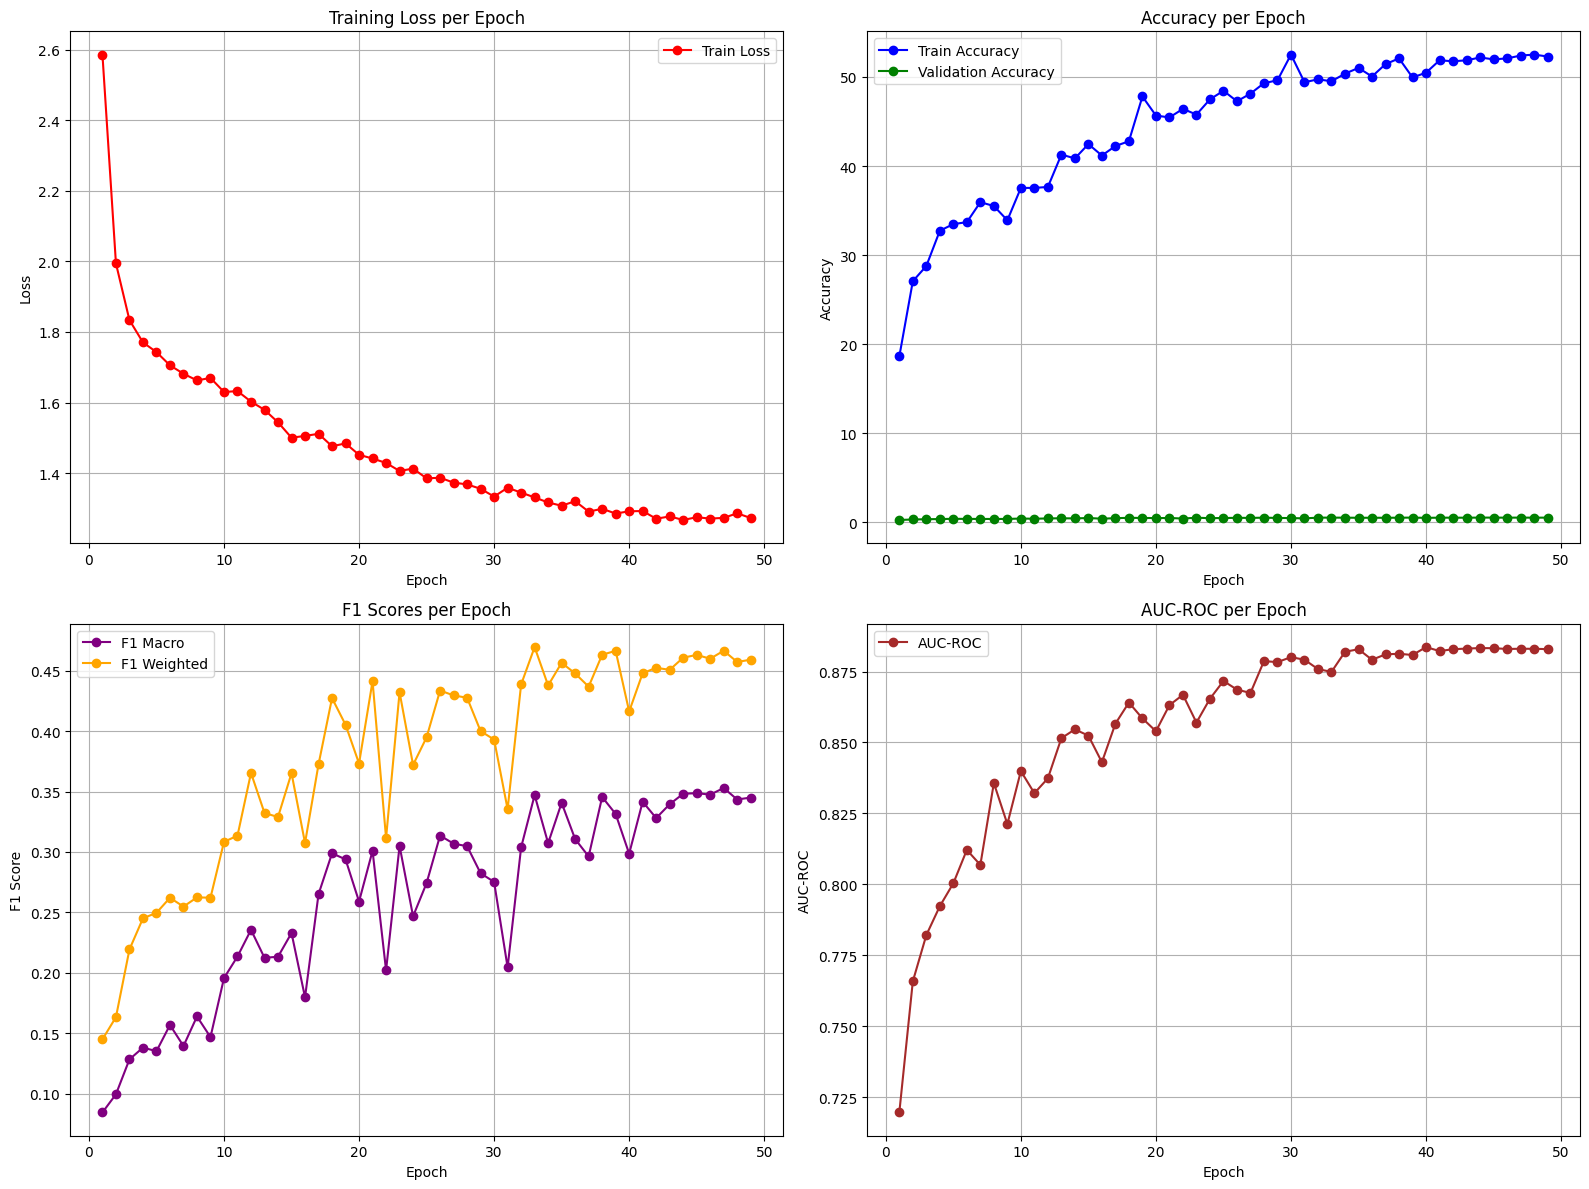

Evaluating: 100%|██████████| 6/6 [00:01<00:00,  5.37it/s]


Best Validation Accuracy: 0.5085

FINAL TEST SET RESULTS

CoOp:
  Top-1 Accuracy: 0.3500
  F1-Score (Macro): 0.2906
  F1-Score (Weighted): 0.2906
  AUC-ROC: 0.8319


<Figure size 640x480 with 0 Axes>

In [23]:
# ============================================================================
# Main Training Pipeline
# ============================================================================

def main():
    # Setup
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Using device: {device}")
    
    # Paths (modify these according to your setup)
    train_csv_path = '/kaggle/input/orthonet-data/train.csv'
    test_csv_path = '/kaggle/input/orthonet-data/test.csv'
    images_root = '/kaggle/input/orthonet-data/orthonet data/orthonet data'
    
    # Load data
    train_df, val_df, test_df = load_and_split_data(train_csv_path, test_csv_path)
    
    # Label encoder
    label_encoder = LabelEncoder()
    label_encoder.fit(train_df['labels'])
    classnames = label_encoder.classes_.tolist()
    num_classes = len(classnames)
    
    print(f"\nNumber of classes: {num_classes}")
    print(f"Classes: {classnames}")
    
    # Load CLIP
    print("\nLoading CLIP model...")
    clip_model, preprocess = clip.load("ViT-B/32", device=device)
    
    # Create datasets
    train_dataset = OrthonetDataset(train_df, images_root, preprocess, label_encoder)
    val_dataset = OrthonetDataset(val_df, images_root, preprocess, label_encoder)
    test_dataset = OrthonetDataset(test_df, images_root, preprocess, label_encoder)
    
    # Create dataloaders
    train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True, num_workers=4)
    val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False, num_workers=4)
    test_loader = DataLoader(test_dataset, batch_size=8, shuffle=False, num_workers=4)
    
    results = {}
    
    # ========== CoOp ==========
    # print("\n" + "="*60)
    # print("Training CoOp")
    # print("="*60)
    # coop_model = CoOpModel(classnames, clip_model, n_ctx=16).to(device)
    # coop_metrics = train_and_evaluate(
    #     coop_model, train_loader, val_loader, test_loader, 
    #     num_classes, device, num_epochs=50, lr=0.002
    # )
    # results['CoOp'] = coop_metrics
    
    # # # ========== CoCoOp ==========
    print("\n" + "="*60)
    print("Training CoCoOp")
    print("="*60)
    cocoop_model = CoCoOpModel(classnames, clip_model, n_ctx=16).to(device)
    cocoop_metrics = train_and_evaluate(
        cocoop_model, train_loader, val_loader, test_loader, 
        num_classes, device, num_epochs=50, lr=0.001
    )
    results['CoCoOp'] = cocoop_metrics
    
    # # Check which parameters will be updated
    # trainable_params = [name for name, param in cocoop_model.named_parameters() if param.requires_grad]
    # print(f"Trainable parameters: {trainable_params}")
    
    # ========== Print Results ==========
    print("\n" + "="*60)
    print("FINAL TEST SET RESULTS")
    print("="*60)
    
    for method_name, metrics in results.items():
        print(f"\n{method_name}:")
        print(f"  Top-1 Accuracy: {metrics['top1_accuracy']:.4f}")
        print(f"  F1-Score (Macro): {metrics['f1_macro']:.4f}")
        print(f"  F1-Score (Weighted): {metrics['f1_weighted']:.4f}")
        print(f"  AUC-ROC: {metrics['auc_roc']:.4f}")
    
    return results


if __name__ == "__main__":
    results = main()

Using device: cuda
Train samples: 935
Validation samples: 234
Test samples: 180

Number of classes: 12
Classes: ['Hip_DepuySynthes_Corail_Collar', 'Hip_DepuySynthes_Corail_NilCol', 'Hip_JRIOrtho_FurlongEvolution_Collar', 'Hip_JRIOrtho_FurlongEvolution_NilCol', 'Hip_SmithAndNephew_Anthology', 'Hip_SmithAndNephew_Polarstem_NilCol', 'Hip_Stryker_AccoladeII', 'Hip_Stryker_Exeter', 'Knee_Depuy_Synthes_Sigma', 'Knee_SmithAndNephew_GenesisII', 'Knee_SmithAndNephew_Legion2', 'Knee_ZimmerBiomet_Oxford']

Loading CLIP model...

Training CoOp
CoOp Initial context: "X X X X X X X X X X X X X X X X"
Number of context words: 16

Trainable parameters:
prompt_learner.ctx torch.Size([16, 512])


Evaluating: 100%|██████████| 30/30 [00:01<00:00, 22.70it/s]



Epoch 1/50
Train Loss: 1.9489, Train Acc: 29.09%
Val Acc: 0.3718, Val F1: 0.1607


Evaluating: 100%|██████████| 30/30 [00:01<00:00, 22.54it/s]



Epoch 2/50
Train Loss: 1.6758, Train Acc: 35.08%
Val Acc: 0.3803, Val F1: 0.1436


...


Epoch 48/50
Train Loss: 0.8268, Train Acc: 73.69%
Val Acc: 0.5940, Val F1: 0.4756


Evaluating: 100%|██████████| 30/30 [00:01<00:00, 22.65it/s]



Epoch 49/50
Train Loss: 0.8265, Train Acc: 73.37%
Val Acc: 0.5897, Val F1: 0.4549


Evaluating: 100%|██████████| 30/30 [00:01<00:00, 22.44it/s]



Epoch 50/50
Train Loss: 0.8254, Train Acc: 73.37%
Val Acc: 0.5897, Val F1: 0.4549


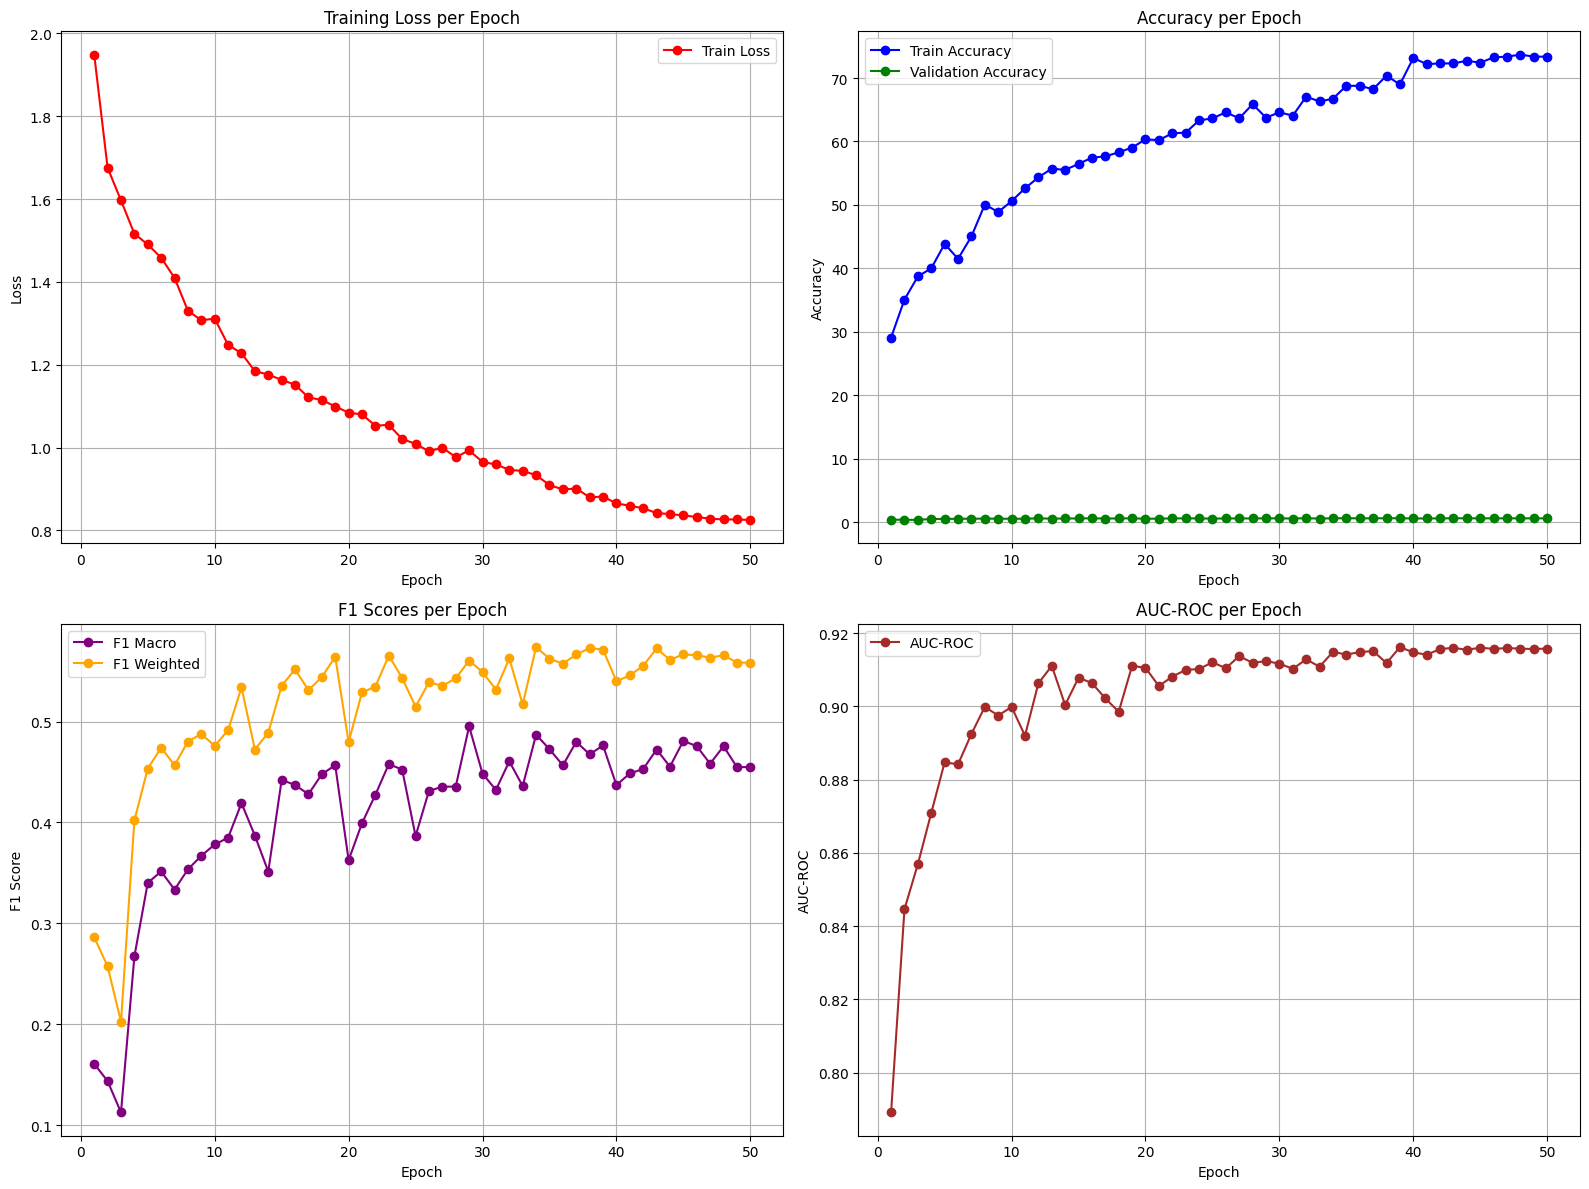

Evaluating: 100%|██████████| 23/23 [00:01<00:00, 21.01it/s]


FINAL TEST SET RESULTS

CoOp:
  Top-1 Accuracy: 0.4278
  F1-Score (Macro): 0.3647
  F1-Score (Weighted): 0.3647
  AUC-ROC: 0.8723


<Figure size 640x480 with 0 Axes>

In [26]:
# ============================================================================
# Main Training Pipeline
# ============================================================================

def main():
    # Setup
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Using device: {device}")
    
    # Paths (modify these according to your setup)
    train_csv_path = '/kaggle/input/orthonet-data/train.csv'
    test_csv_path = '/kaggle/input/orthonet-data/test.csv'
    images_root = '/kaggle/input/orthonet-data/orthonet data/orthonet data'
    
    # Load data
    train_df, val_df, test_df = load_and_split_data(train_csv_path, test_csv_path)
    
    # Label encoder
    label_encoder = LabelEncoder()
    label_encoder.fit(train_df['labels'])
    classnames = label_encoder.classes_.tolist()
    num_classes = len(classnames)
    
    print(f"\nNumber of classes: {num_classes}")
    print(f"Classes: {classnames}")
    
    # Load CLIP
    print("\nLoading CLIP model...")
    clip_model, preprocess = clip.load("ViT-B/32", device=device)
    
    # Create datasets
    train_dataset = OrthonetDataset(train_df, images_root, preprocess, label_encoder)
    val_dataset = OrthonetDataset(val_df, images_root, preprocess, label_encoder)
    test_dataset = OrthonetDataset(test_df, images_root, preprocess, label_encoder)
    
    # Create dataloaders
    train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True, num_workers=4)
    val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False, num_workers=4)
    test_loader = DataLoader(test_dataset, batch_size=8, shuffle=False, num_workers=4)
    
    results = {}
    
    # ========== CoOp ==========
    print("\n" + "="*60)
    print("Training CoOp")
    print("="*60)
    coop_model = CoOpModel(classnames, clip_model, n_ctx=16).to(device)
    coop_metrics = train_and_evaluate(
        coop_model, train_loader, val_loader, test_loader, 
        num_classes, device, num_epochs=50, lr=0.001
    )
    results['CoOp'] = coop_metrics
    
    # # # ========== CoCoOp ==========
    # print("\n" + "="*60)
    # print("Training CoCoOp")
    # print("="*60)
    # cocoop_model = CoCoOpModel(classnames, clip_model, n_ctx=16).to(device)
    # cocoop_metrics = train_and_evaluate(
    #     cocoop_model, train_loader, val_loader, test_loader, 
    #     num_classes, device, num_epochs=50, lr=0.001
    # )
    # results['CoCoOp'] = cocoop_metrics
    
    # # Check which parameters will be updated
    # trainable_params = [name for name, param in cocoop_model.named_parameters() if param.requires_grad]
    # print(f"Trainable parameters: {trainable_params}")
    
    # ========== Print Results ==========
    print("\n" + "="*60)
    print("FINAL TEST SET RESULTS")
    print("="*60)
    
    for method_name, metrics in results.items():
        print(f"\n{method_name}:")
        print(f"  Top-1 Accuracy: {metrics['top1_accuracy']:.4f}")
        print(f"  F1-Score (Macro): {metrics['f1_macro']:.4f}")
        print(f"  F1-Score (Weighted): {metrics['f1_weighted']:.4f}")
        print(f"  AUC-ROC: {metrics['auc_roc']:.4f}")
    
    return results


if __name__ == "__main__":
    results = main()